<a href="https://colab.research.google.com/github/jacobhroutzong/Reinforcement-Learning/blob/main/Reinforcement_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install gymnasium pygame

In [ ]:
import gymnasium as gym

env = gym.make('FrozenLake-v1', is_slippery=False)

print(f"Observation Space: {env.observation_space}")
print(f"Action Space: {env.action_space}")

Observation Space: Discrete(16)
Action Space: Discrete(4)


Episode: 2000, Epsilon: 0.8000
Episode: 4000, Epsilon: 0.6000
Episode: 6000, Epsilon: 0.4000
Episode: 8000, Epsilon: 0.2000
Episode: 10000, Epsilon: 0.0100
Episode: 12000, Epsilon: 0.0100
Episode: 14000, Epsilon: 0.0100
Episode: 16000, Epsilon: 0.0100
Episode: 18000, Epsilon: 0.0100
Episode: 20000, Epsilon: 0.0100
Training finished.



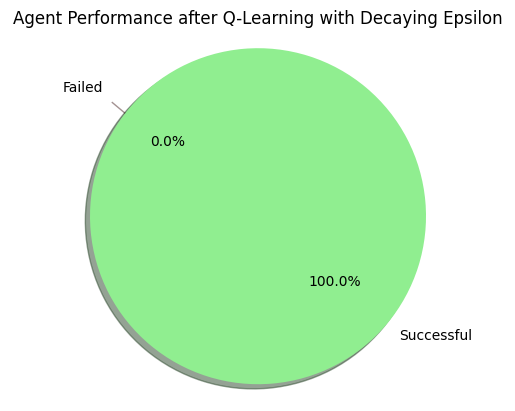

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import gymnasium as gym
import random

# Create the environment
env = gym.make('FrozenLake-v1', is_slippery=False)

# Initialize the Q-table
q_table = np.zeros([env.observation_space.n, env.action_space.n])

# Hyperparameters
alpha = 0.1 # Learning rate
gamma = 0.99 # Discount factor
epsilon = 1.0 # Initial epsilon
epsilon_decay_rate = 0.0001 # Epsilon decay rate
min_epsilon = 0.01 # Minimum epsilon

# Training the Agent with decaying epsilon
for i in range(1, 20001):
    state, info = env.reset()

    done = False
    truncated = False

    while not done and not truncated:
        if random.uniform(0, 1) < epsilon:
            action = env.action_space.sample() # Explore action space
        else:
            action = np.argmax(q_table[state]) # Exploit learned values

        next_state, reward, done, truncated, info = env.step(action)

        old_value = q_table[state, action]
        next_max = np.max(q_table[next_state])

        new_value = (1 - alpha) * old_value + alpha * (reward + gamma * next_max)
        q_table[state, action] = new_value

        state = next_state

    # Decay epsilon
    epsilon = max(min_epsilon, epsilon - epsilon_decay_rate)

    if i % 2000 == 0:
        print(f"Episode: {i}, Epsilon: {epsilon:.4f}")

print("Training finished.\n")

# Evaluating the Agent
episodes_to_run = 100
successful_episodes = 0

for _ in range(episodes_to_run):
    state, info = env.reset()
    done = False
    truncated = False

    while not done and not truncated:
        action = np.argmax(q_table[state])
        state, reward, done, truncated, info = env.step(action)

        if reward == 1:
            successful_episodes += 1

failed_episodes = episodes_to_run - successful_episodes

# Data for plotting
labels = 'Successful', 'Failed'
sizes = [successful_episodes, failed_episodes]
colors = ['lightgreen', 'lightcoral']
explode = (0.1, 0)  # explode 1st slice

# Plot
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
        autopct='%1.1f%%', shadow=True, startangle=140)

plt.axis('equal')
plt.title("Agent Performance after Q-Learning with Decaying Epsilon")
plt.show()

That was Value-Based RL (Q-Learning). Now we'll explore Policy Gradient-Based RL (REINFORCE).

In [ ]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import numpy as np
import matplotlib.pyplot as plt

# Hyperparameters
learning_rate = 0.01
gamma = 0.99  # Discount factor
num_episodes = 1000
seed = 42

# Set seeds for reproducibility
np.random.seed(seed)
torch.manual_seed(seed)

In [ ]:
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, action_dim)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        return self.fc2(x)  # Logits for softmax

In [ ]:
env = gym.make('CartPole-v1')
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy = PolicyNetwork(state_dim, action_dim)
optimizer = optim.Adam(policy.parameters(), lr=learning_rate)

episode_rewards = []  # To track rewards

for episode in range(num_episodes):
    state, _ = env.reset(seed=seed + episode)  # Vary seed
    state = torch.tensor(state, dtype=torch.float32)

    log_probs = []
    rewards = []
    done = False

    # Rollout episode
    while not done:
        logits = policy(state)
        dist = Categorical(logits=logits)
        action = dist.sample()
        log_probs.append(dist.log_prob(action))

        next_state, reward, terminated, truncated, _ = env.step(action.item())
        rewards.append(reward)
        state = torch.tensor(next_state, dtype=torch.float32)
        done = terminated or truncated

    episode_rewards.append(sum(rewards))

    # Compute discounted returns
    returns = []
    G = 0
    for r in reversed(rewards):
        G = r + gamma * G
        returns.insert(0, G)
    returns = torch.tensor(returns, dtype=torch.float32)

    # Normalize returns (baseline)
    returns = (returns - returns.mean()) / (returns.std() + 1e-8)

    # Compute loss
    loss = 0
    for log_prob, G in zip(log_probs, returns):
        loss += -log_prob * G  # Negative for ascent

    # Update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Progress
    if (episode + 1) % 100 == 0:
        avg_reward = np.mean(episode_rewards[-100:])
        print(f'Episode {episode + 1}/{num_episodes}, Avg Reward (last 100): {avg_reward:.2f}')

env.close()

Episode 100/1000, Avg Reward (last 100): 9.53
Episode 200/1000, Avg Reward (last 100): 44.47
Episode 300/1000, Avg Reward (last 100): 58.33
Episode 400/1000, Avg Reward (last 100): 334.42
Episode 500/1000, Avg Reward (last 100): 336.69
Episode 600/1000, Avg Reward (last 100): 32.65
Episode 700/1000, Avg Reward (last 100): 91.90
Episode 800/1000, Avg Reward (last 100): 474.45
Episode 900/1000, Avg Reward (last 100): 417.59
Episode 1000/1000, Avg Reward (last 100): 357.73


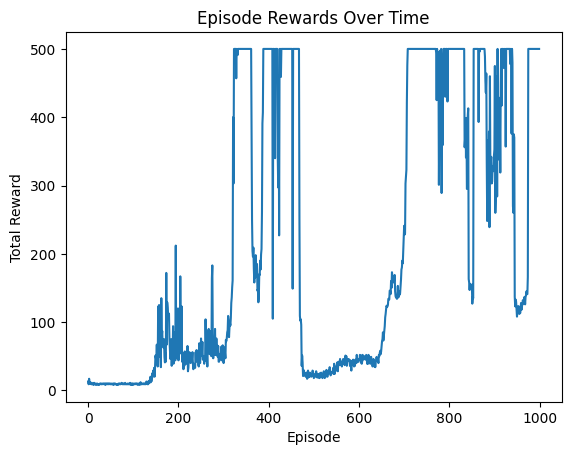

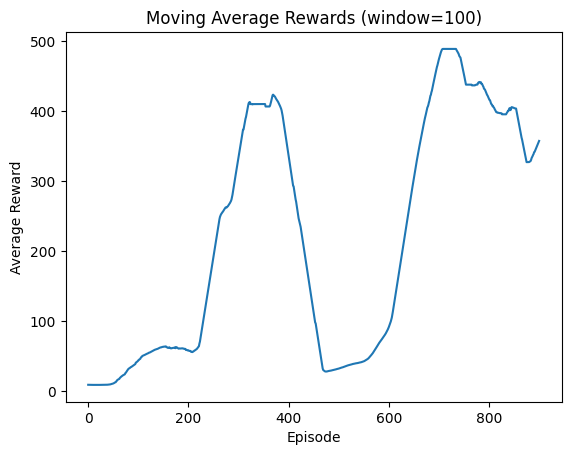

In [ ]:
plt.plot(episode_rewards)
plt.title('Episode Rewards Over Time')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

# Moving average
window_size = 100
moving_avg = np.convolve(episode_rewards, np.ones(window_size)/window_size, mode='valid')
plt.plot(moving_avg)
plt.title('Moving Average Rewards (window=100)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.show()